In [96]:
%load_ext autoreload
%autoreload 2

import os

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.colors as mcl

from files import data, features

from collections import Counter

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
# Make sure this matches project root every time

ROOT = '..'

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(ROOT)

os.environ["DATA_DIR"] = "datasets"

In [35]:
listings = data.load("listings")

off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [36]:
', '.join(listings.columns)

'ml_num, sold_price, list_price, date_listed, date_sold, days_on_market, house_type_name, house_style, bedrooms, washrooms, parking_total, garage, house_area, lot_front, lot_depth, municipality, community, latitude, longitude, external_avm_estimate, external_avm_estimate_date, remarks'

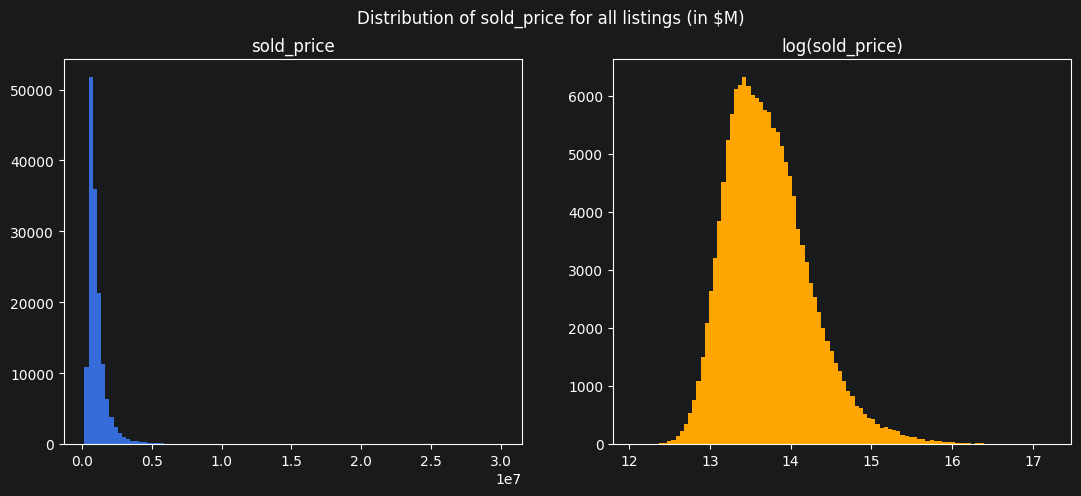

In [37]:
fig, axes = plt.subplots(1, 2, figsize = (13, 5))

axes[0].hist(listings['sold_price'], bins = 100)
axes[0].set(title = 'sold_price')

axes[1].hist(np.log(listings['sold_price']), bins = 100, color = 'orange')
axes[1].set(title = 'log(sold_price)')

plt.suptitle('Distribution of sold_price for all listings (in $M)')
plt.show()

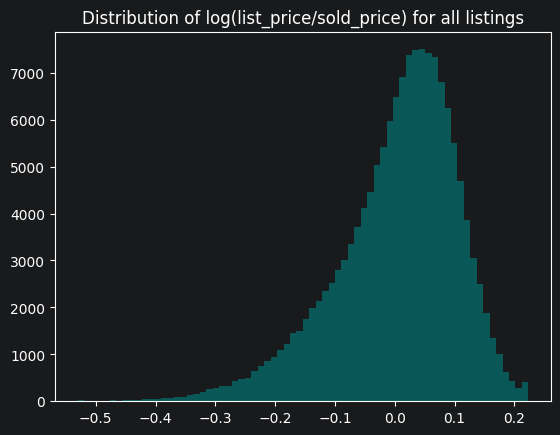

In [38]:
plt.hist(np.log(listings['list_price']) - np.log(listings['sold_price']), bins = 70, color = 'teal', alpha = 0.6)

plt.title('Distribution of log(list_price/sold_price) for all listings')

plt.show()

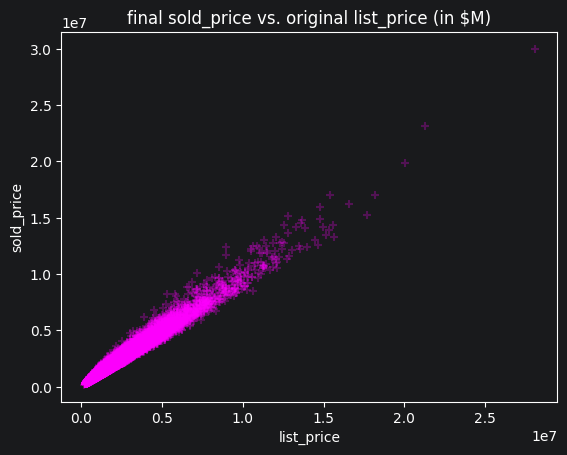

In [39]:
plt.scatter('list_price', 'sold_price', data = listings, marker = '+', color = 'magenta', alpha = 0.25)

plt.title('final sold_price vs. original list_price (in $M)')

plt.xlabel('list_price')
plt.ylabel('sold_price')

plt.show()

In [40]:
avm_est_available = listings[listings['external_avm_estimate_date'] < listings['date_sold']]

print(f'{len(avm_est_available)} records with external_avm_estimate available before date_sold')
print(f'({np.round(len(avm_est_available) / len(listings) * 100, 2)}% of complete dataset)')

44716 records with external_avm_estimate available before date_sold
(29.81% of complete dataset)


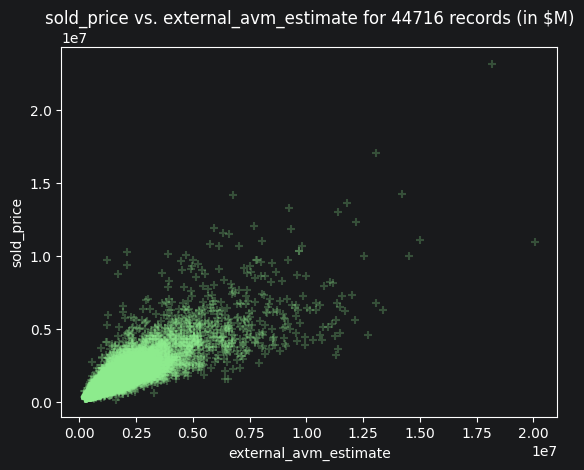

In [41]:
plt.scatter('external_avm_estimate', 'sold_price', data = avm_est_available, marker = '+', color = 'lightgreen', alpha = 0.25)

plt.title(f'sold_price vs. external_avm_estimate for {len(avm_est_available)} records (in $M)')

plt.xlabel('external_avm_estimate')
plt.ylabel('sold_price')

plt.show()

In [42]:
listings[['house_type_name', 'sold_price']].groupby('house_type_name').describe().round(2)

sold_price                                               \
                        count        mean         std       min        25%   
house_type_name                                                              
Co-Op Apt               729.0   755315.64   556019.33  262700.0   519400.0   
Condo Apt             76374.0   699026.08   277399.40  172600.0   530500.0   
Condo Townhouse       10160.0   842632.68   273856.26  336700.0   656875.0   
Detached              43202.0  1688777.61  1153124.38  205900.0  1054100.0   
Freehold Townhouse     5138.0  1283139.04   506767.35  558800.0   957725.0   
Semi-Detached         14397.0  1322291.15   565621.88  454600.0   981700.0   

                                                      
                          50%        75%         max  
house_type_name                                       
Co-Op Apt            646600.0   838200.0   9703100.0  
Condo Apt            644300.0   799100.0  10300300.0  
Condo Townhouse      786200.0   962000.0   3406000.0  
Detached            1367850.0  1895175.0  30000000.0  
Freehold Townhouse  1146600.0  1451125.0   8827900.0  
Semi-Detached       1179100.0  1485600.0  11839300.0

In [43]:
listings[['municipality', 'sold_price']].groupby('municipality').describe().round(2)

sold_price                                                       \
                  count        mean        std       min       25%       50%   
municipality                                                                   
Etobicoke       14315.0   931949.44  585444.51  206400.0  552400.0  742600.0   
North York      27555.0  1038978.84  782344.91  221600.0  619600.0  835800.0   
Scarborough     21078.0  1028169.12  790277.90  205900.0  593900.0  814100.0   
Toronto         85323.0  1124122.95  860821.73  172600.0  649200.0  894600.0   
York             1729.0   886261.42  363870.70  292900.0  621300.0  786200.0   

                                     
                    75%         max  
municipality                         
Etobicoke     1107600.0   9946400.0  
North York    1190400.0  30000000.0  
Scarborough   1204400.0  23145600.0  
Toronto       1288500.0  17035700.0  
York          1066000.0   3976300.0

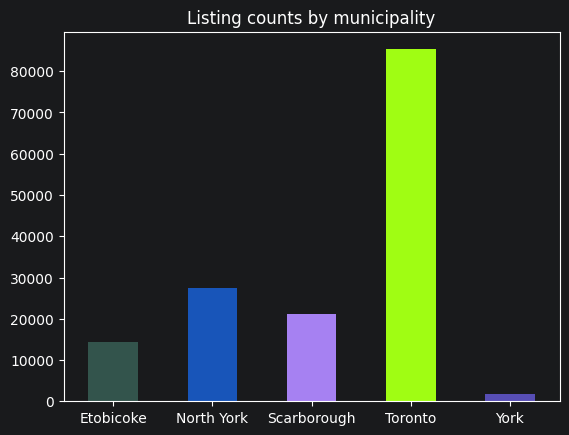

municipality
Toronto        85323
North York     27555
Scarborough    21078
Etobicoke      14315
York            1729
Name: count, dtype: int64


In [44]:
np.random.seed(91)

muni_counts = listings['municipality'].value_counts()

muni_colors = [mcl.to_hex(color) for color in np.random.rand(len(muni_counts), 3)]

muni_counts.sort_index().plot(kind = 'bar', rot = 0, color = muni_colors)

plt.title('Listing counts by municipality')
plt.xlabel(None)

plt.show()

print(muni_counts)

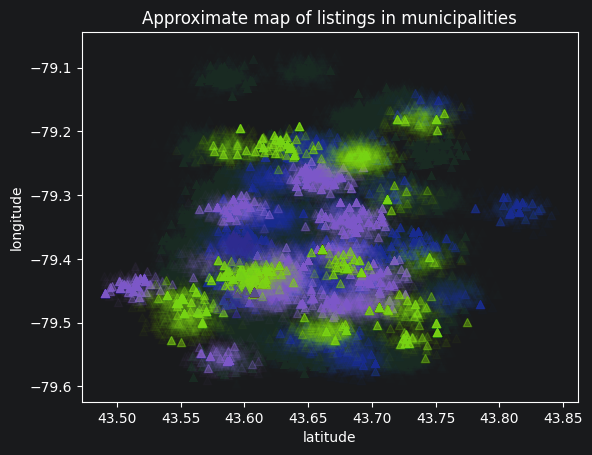

In [45]:
for i, muni in enumerate(muni_counts.index):
    plt.scatter('latitude', 'longitude', data = listings[listings['municipality'] == muni],
                marker = '^', color = muni_colors[i], alpha = 0.025)

plt.title(f'Approximate map of listings in municipalities')

plt.xlabel('latitude')
plt.ylabel('longitude')

plt.show()

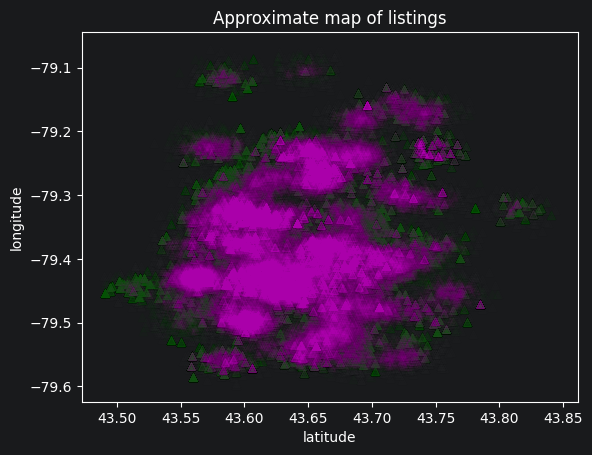

In [46]:
plt.scatter('latitude', 'longitude', data = listings, marker = '^', color = 'green', alpha = 0.025)

plt.scatter('latitude', 'longitude', data = listings[listings['sold_price'] > listings['sold_price'].median()],
            marker = '^', color = 'magenta', alpha = 0.0125)

plt.title(f'Approximate map of listings')

plt.xlabel('latitude')
plt.ylabel('longitude')

plt.show()

In [47]:
month_group = listings['date_sold'].dt.to_period('M')

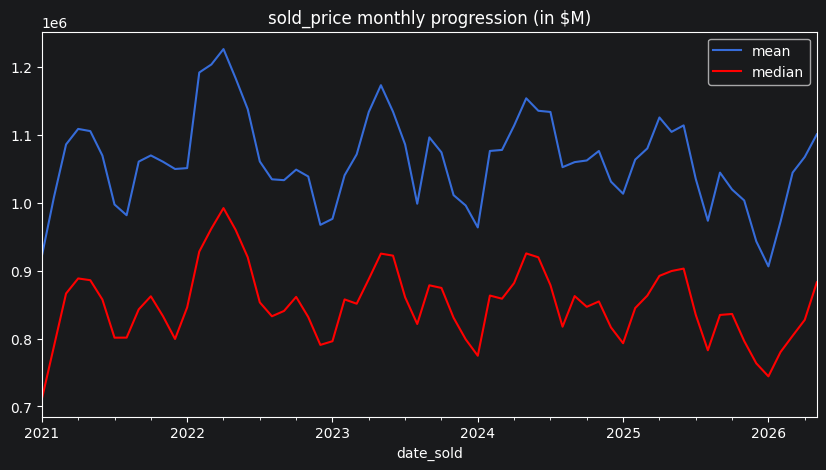

In [48]:
listings['sold_price'].groupby(month_group).mean().plot(figsize = (10, 5), kind = 'line', label = 'mean')
listings['sold_price'].groupby(month_group).median().plot(figsize = (10, 5), kind = 'line', label = 'median', color = 'red')

plt.title("sold_price monthly progression (in $M)")

plt.legend()

plt.show()

In [99]:
listings['sold_price_per_sqft'] = listings['sold_price'] / features.square_feet(listings['house_area'])

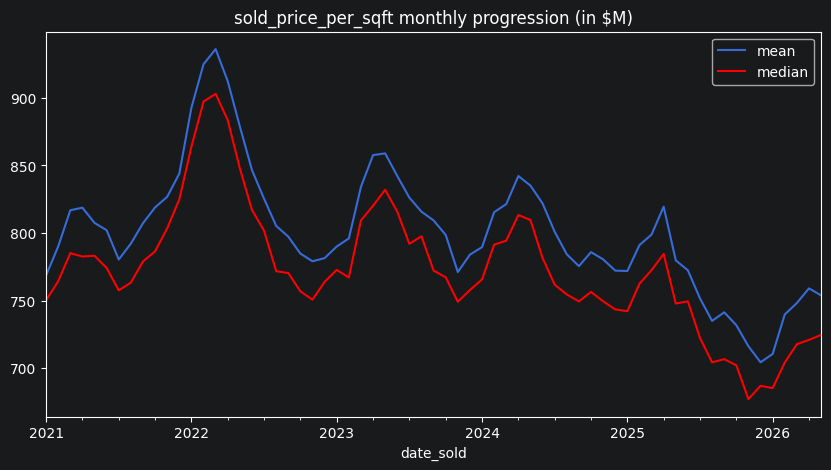

In [102]:
listings['sold_price_per_sqft'].groupby(month_group).mean().plot(figsize = (10, 5), kind = 'line', label = 'mean')
listings['sold_price_per_sqft'].groupby(month_group).median().plot(figsize = (10, 5), kind = 'line', label = 'median', color = 'red')

plt.title("sold_price_per_sqft monthly progression (in $M)")

plt.legend()

plt.show()

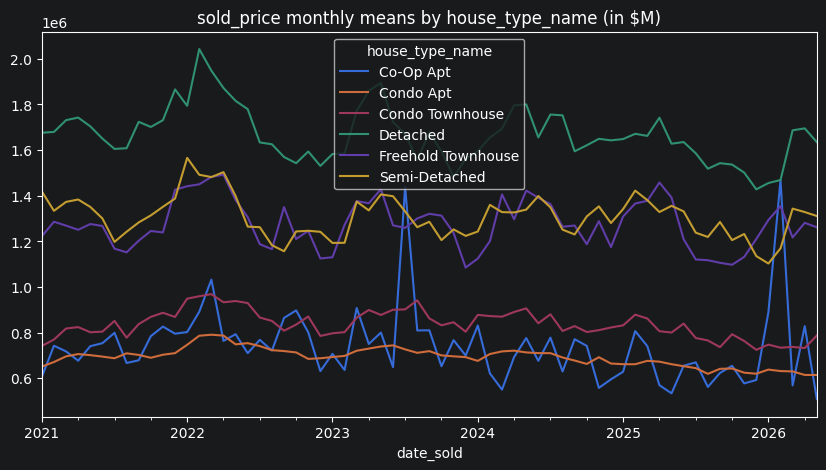

In [49]:
listings[['house_type_name', 'sold_price']].groupby([month_group, 'house_type_name'])['sold_price'].mean().unstack().plot(figsize = (10, 5))

plt.title("sold_price monthly means by house_type_name (in $M)")

plt.show()

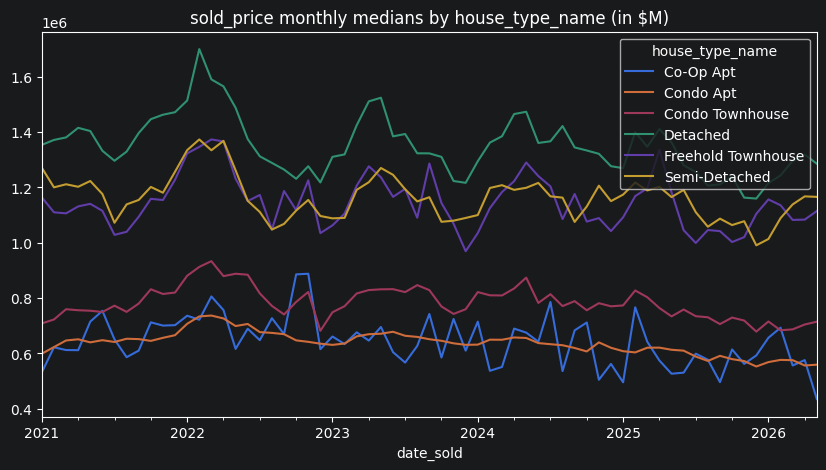

In [50]:
listings[['house_type_name', 'sold_price']].groupby([month_group, 'house_type_name'])['sold_price'].median().unstack().plot(figsize = (10, 5))

plt.title("sold_price monthly medians by house_type_name (in $M)")

plt.show()

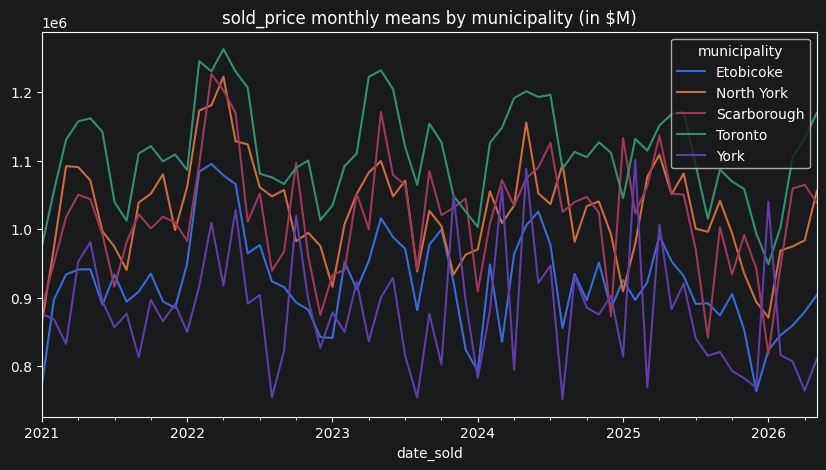

In [51]:
listings[['municipality', 'sold_price']].groupby([month_group, 'municipality'])['sold_price'].mean().unstack().plot(figsize = (10, 5))

plt.title("sold_price monthly means by municipality (in $M)")

plt.show()

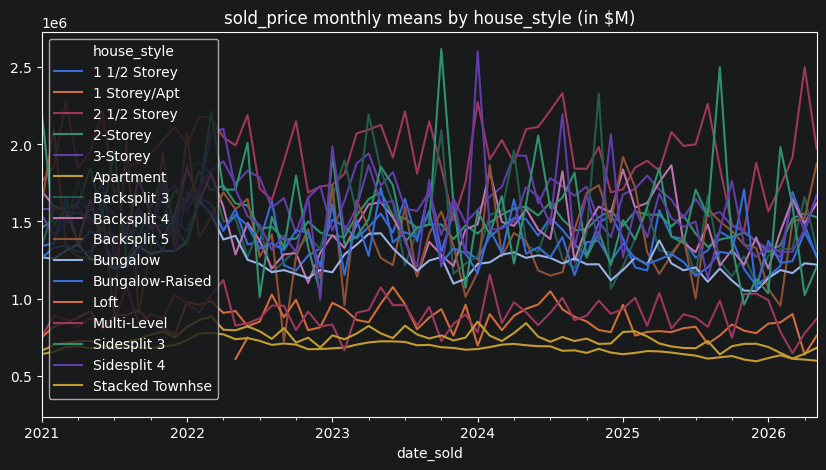

In [52]:
listings[['house_style', 'sold_price']].groupby([month_group, 'house_style'])['sold_price'].mean().unstack().plot(figsize = (10, 5))

plt.title("sold_price monthly means by house_style (in $M)")

plt.show()

In [53]:
((listings['date_sold'] - listings['date_listed']).dt.days == listings['days_on_market']).sum()

np.int64(150000)

In [54]:
listings['remarks'].str.split().str.len()

0         49
1         86
2         41
3         55
4         67
          ..
149995    69
149996    48
149997    69
149998    69
149999    60
Name: remarks, Length: 150000, dtype: int64

In [55]:
((pd.notna(listings['lot_front'])) & (pd.notna(listings['lot_depth']))).sum()

np.int64(62737)

In [56]:
len(listings[pd.notna(listings).all(axis = 1)])

62309

In [57]:
amenities_and_price = pd.concat([listings[['bedrooms', 'washrooms', 'parking_total', 'garage']].sum(axis = 1).astype(int),
                                 listings['sold_price']], axis = 1)

amenities_and_price.columns = ['num_amenities', 'sold_price']

amen_means = amenities_and_price.groupby('num_amenities')['sold_price'].mean()
amen_medis = amenities_and_price.groupby('num_amenities')['sold_price'].median()

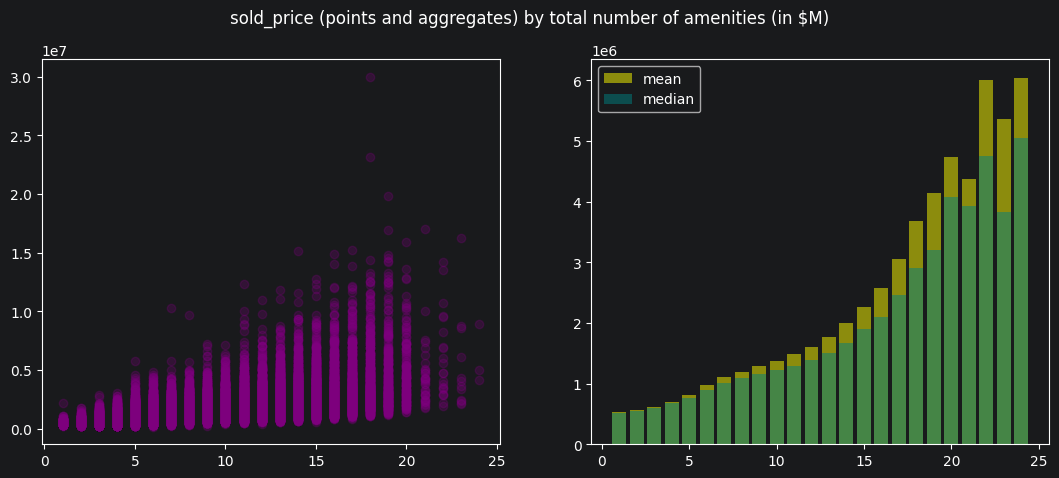

In [58]:
fig, axes = plt.subplots(1, 2, figsize = (13, 5))

axes[0].scatter('num_amenities', 'sold_price', data = amenities_and_price, color = 'purple', alpha = 0.25)

axes[1].bar(x = amen_means.index, height = amen_means, color = 'yellow', alpha = 0.5, label = 'mean')
axes[1].bar(x = amen_medis.index, height = amen_medis, color = 'teal', alpha = 0.5, label = 'median')

axes[1].legend()

plt.suptitle("sold_price (points and aggregates) by total number of amenities (in $M)")
plt.show()

In [59]:
amenities_and_price[amenities_and_price['num_amenities'] == 1].sort_values(by = ['sold_price'], ascending = False)

,num_amenities,sold_price
92640,1,2170900.0
15027,1,1103200.0
76362,1,1050300.0
10438,1,1048600.0
1345,1,1020500.0
...,...,...
28030,1,309600.0
146000,1,302000.0
8073,1,289600.0
145045,1,276200.0


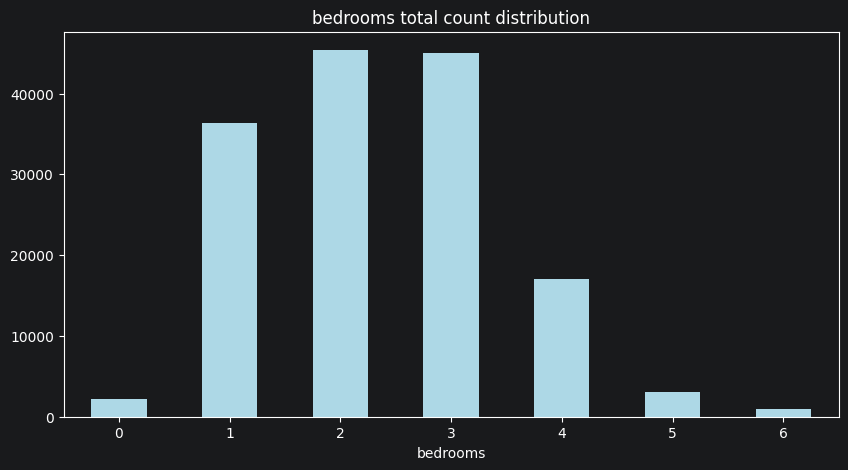

In [60]:
listings['bedrooms'].astype(int).value_counts().sort_index().plot(kind = 'bar', figsize = (10, 5), color = 'lightblue', rot = 0)

plt.title("bedrooms total count distribution")

plt.show()

In [61]:
listings['remarks_clean'] = listings['remarks'].str.lower().str.replace(r"[^\w\s]", "", regex = True)

complete_word_counts = pd.Series(Counter(' '.join(listings['remarks_clean']).split())).sort_values(ascending = False)

In [62]:
complete_word_counts

a                   473263
and                 441729
the                 336373
for                 278031
this                191935
                     ...  
745squarefoot            1
entertainimagine         1
21by101foot              1
updatedwindows           1
49x159foot               1
Length: 17622, dtype: int64